## Clustering: KMeans++

- **Se ejecuta en Spark (MLlib):** el costo es O(n · k · iteraciones), escala a todos los proveedores
- Inicialización `k-means||`: versión paralela de k-means++ (misma garantía de buena semilla, en pocas pasadas)
- Criterio de k: **codo** (WSSSE) + **silueta**; se elige la mejor silueta con k ≥ 3 (k = 2 suele separar solo
  "grandes vs pequeños" y no da tipologías)
- La **distancia al centroide** sirve como primer puntaje de anomalía

### Imports

In [1]:
import os, socket, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, Window, functions as F

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_columns", 40)

### Utilidades

- Constantes

In [2]:
SECCION, NOTEBOOK = "02_Clustering", "b_kmeans"

proyecto = Path.cwd()
while not (proyecto / "docker-compose.yml").exists() and proyecto != proyecto.parent:
    proyecto = proyecto.parent

final_dir = proyecto / "data" / "final"
artef_dir = proyecto / "data" / "artefactos"
clus_dir  = proyecto / "data" / "clustering"
clus_dir.mkdir(parents=True, exist_ok=True)
SUJETOS = {"entidad": "entidad_key", "proveedor": "proveedor_key"}
SEED = 42

out_dir = proyecto / SECCION / "temp" / NOTEBOOK
fig_dir, tab_dir, web_dir = out_dir / "figs", out_dir / "tablas", out_dir / "web"
for d in (fig_dir, tab_dir, web_dir):
    d.mkdir(parents=True, exist_ok=True)

def mostrar_fig(nombre):
    plt.tight_layout()
    plt.savefig(fig_dir / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

def guardar_tabla(df, nombre):
    sdf = spark.createDataFrame(df) if isinstance(df, pd.DataFrame) else df
    sdf.coalesce(1).write.mode("overwrite").parquet(str(tab_dir / nombre))
    sdf.toPandas().to_json(web_dir / f"{nombre}.json", orient="records", force_ascii=False, date_format="iso", indent=1)
    return len(df) if isinstance(df, pd.DataFrame) else sdf.count()

def leer(directorio, nombre):
    return spark.read.parquet(str(directorio / nombre))

- Spark

In [3]:
spark_master = os.environ.get("spark_master", "local[*]")

builder = (SparkSession.builder
           .appName(NOTEBOOK)
           .master(spark_master)
           .config("spark.driver.memory",   os.environ.get("SPARK_DRIVER_MEMORY", "4g"))
           .config("spark.executor.memory", os.environ.get("SPARK_EXECUTOR_MEMORY", "4g"))
           .config("spark.sql.shuffle.partitions", "24")
           .config("spark.ui.showConsoleProgress", "false")
           .config("spark.sql.session.timeZone", "America/Lima")
           .config("spark.sql.execution.arrow.pyspark.enabled", "true"))

if spark_master.startswith("spark://"):
    builder = (builder.config("spark.driver.host", socket.gethostname())
                      .config("spark.driver.bindAddress", "0.0.0.0"))

spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

### Verificación del cluster

In [4]:
sc = spark.sparkContext
estado = sc._jsc.sc().getExecutorMemoryStatus()
print(f"Master        : {sc.master}")
print(f"Executors     : {estado.size() - 1}")
print(f"Cores totales : {sc.defaultParallelism}")
print(f"Memoria driver: {sc._jvm.java.lang.Runtime.getRuntime().maxMemory() / 1024**3:.1f} GB")
print("UI del job    : http://localhost:4040")

Master        : spark://spark-master:7077
Executors     : 0
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

In [5]:
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml.functions import vector_to_array

config = json.loads((clus_dir / "config.json").read_text())
K_RANGO = list(range(2, 13))
K_FIJO = {"entidad": None, "proveedor": None}   # fijar a mano si el codo sugiere otro k
N_WEB = 3000
prep = {s: leer(clus_dir, f"prep_{s}").cache() for s in config}
for s, d in prep.items():
    print(f"{s}: {d.count():,} puntos, {config[s]['n_comp']} componentes")

entidad: 2,695 puntos, 6 componentes
proveedor: 5,865 puntos, 7 componentes


In [6]:
def rasgos(z, cols, top=3, prefijo=""):
    # describe un punto o un clúster por sus features más alejadas de la media (en desviaciones estándar)
    z = z[cols].astype(float)
    orden = z.abs().sort_values(ascending=False).index[:top]
    return ", ".join(f"{c[len(prefijo):]} {'↑' if z[c] > 0 else '↓'}{abs(z[c]):.1f}σ" for c in orden)

---
### 1. Barrido de k

In [7]:
evaluador = ClusteringEvaluator(featuresCol="pca", predictionCol="cluster", metricName="silhouette",
                                distanceMeasure="squaredEuclidean")
curvas, muestras, modelos = [], {}, {}
for s, df in prep.items():
    key = config[s]["key"]
    n = df.count()
    muestra = (df.sample(fraction=min(1.0, N_WEB / n), seed=SEED) if n > N_WEB else df).select(key, "nombre", "pc1", "pc2", "pca").cache()
    mpd = muestra.select(key, "nombre", "pc1", "pc2").toPandas()
    for k in K_RANGO:
        t0 = time.time()
        m = KMeans(k=k, seed=SEED, featuresCol="pca", predictionCol="cluster", initMode="k-means||", maxIter=50).fit(df)
        sil = evaluador.evaluate(m.transform(df))
        curvas.append({"sujeto": s, "k": k, "wssse": m.summary.trainingCost, "silhouette": sil, "seg": round(time.time() - t0, 1)})
        mpd = mpd.merge(m.transform(muestra).select(key, F.col("cluster").alias(f"k{k}")).toPandas(), on=key)
        modelos[(s, k)] = m
    muestras[s] = mpd
curvas = pd.DataFrame(curvas)
curvas

,sujeto,k,wssse,silhouette,seg
0,entidad,2,19711.243965,0.373244,10.4
1,entidad,3,17213.635569,0.374623,3.0
2,entidad,4,15387.515295,0.303004,5.5
3,entidad,5,13956.642142,0.283326,4.4
4,entidad,6,11431.938930,0.337486,3.2
5,entidad,7,10614.111817,0.311564,5.1
6,entidad,8,10093.125871,0.277369,4.8
7,entidad,9,9387.968806,0.313484,4.5
8,entidad,10,9290.230791,0.311243,3.1
9,entidad,11,8711.734337,0.312657,2.5


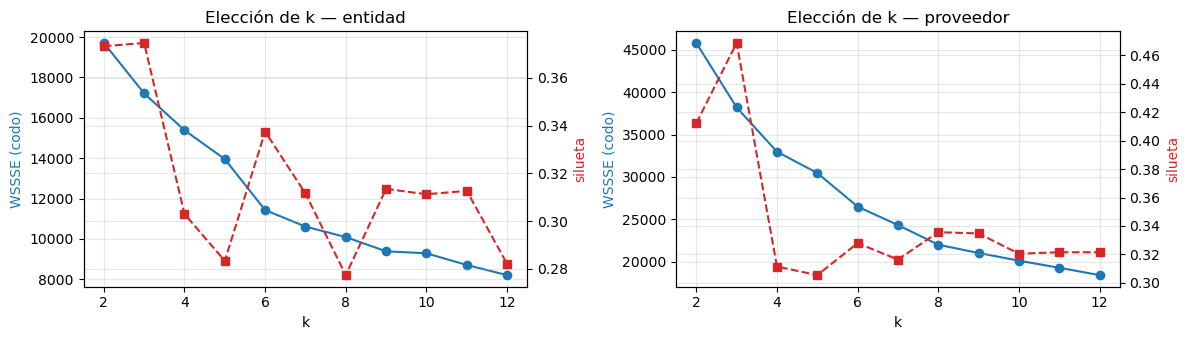

k elegido: {'entidad': 3, 'proveedor': 3}


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for i, s in enumerate(prep):
    c = curvas[curvas.sujeto == s]
    ax[i].plot(c.k, c.wssse, "o-", color="tab:blue"); ax[i].set_ylabel("WSSSE (codo)", color="tab:blue")
    a2 = ax[i].twinx(); a2.plot(c.k, c.silhouette, "s--", color="tab:red"); a2.set_ylabel("silueta", color="tab:red")
    ax[i].set_title(f"Elección de k — {s}"); ax[i].set_xlabel("k")
mostrar_fig("eleccion_k")

k_sel = {}
for s in prep:
    c = curvas[(curvas.sujeto == s) & (curvas.k >= 3)].reset_index(drop=True)
    k_sel[s] = K_FIJO[s] or int(c.loc[c.silhouette.idxmax(), "k"])
    config[s]["k"] = k_sel[s]
(clus_dir / "config.json").write_text(json.dumps(config, indent=1))
print("k elegido:", k_sel)

- La silueta de Spark es la versión simplificada (distancia a centroides): sirve para comparar k, no como valor absoluto
- k elegido: ‹k_entidad› entidades, ‹k_proveedor› proveedores. Si el codo es claro en otro k, se fija en `K_FIJO`
  y se justifica

---
### 2. Modelo final, perfiles y distancia al centroide

In [9]:
perfiles, perfiles_z, top_dist = [], [], []
for s, df in prep.items():
    key, feats, k = config[s]["key"], config[s]["feats"], k_sel[s]
    monto = "monto_adjudicado_total" if s == "entidad" else "monto_total"
    m = modelos[(s, k)]
    centros = spark.createDataFrame([(i, [float(v) for v in c]) for i, c in enumerate(m.clusterCenters())], ["cluster", "centro"])
    pred = (m.transform(df).join(F.broadcast(centros), "cluster")
              .withColumn("_x", vector_to_array("pca"))
              .withColumn("dist_centro", F.sqrt(F.aggregate(F.zip_with("_x", "centro", lambda a, b: (a - b) * (a - b)),
                                                            F.lit(0.0), lambda acc, v: acc + v)))
              .drop("_x", "centro"))
    pred.select(key, "cluster", "dist_centro").write.mode("overwrite").parquet(str(clus_dir / f"kmeans_{s}"))
    pred = leer(clus_dir, f"kmeans_{s}").join(df, key)

    pz = (pred.withColumn("_z", vector_to_array("features_std")).groupBy("cluster")
              .agg(*[F.avg(F.col("_z")[i]).alias(f) for i, f in enumerate(feats)]).orderBy("cluster").toPandas())
    pz["rasgos"] = pz.apply(lambda r: rasgos(r, feats), axis=1)
    pr = (pred.groupBy("cluster").agg(F.count("*").alias("n"),
              F.expr("percentile_approx(n_procesos, 0.5)").alias("mediana_procesos"),
              F.expr(f"percentile_approx({monto}, 0.5)").alias("mediana_monto"),
              F.sum(monto).alias("monto_cluster"),
              *[F.round(F.avg(f), 3).alias(f) for f in feats if not f.startswith("log_")])
            .orderBy("cluster").toPandas())
    pr["pct_actores"] = (100 * pr.n / pr.n.sum()).round(1)
    pr["pct_monto"] = (100 * pr.monto_cluster / pr.monto_cluster.sum()).round(1)
    pr = pr.merge(pz[["cluster", "rasgos"]], on="cluster")
    pr.insert(0, "sujeto", s); pz.insert(0, "sujeto", s)
    perfiles.append(pr); perfiles_z.append(pz)
    print(f"=== {s} (k={k})"); display(pr)

    td = (pred.orderBy(F.desc("dist_centro")).limit(20)
              .select(F.lit(s).alias("sujeto"), F.col(key).alias("clave"), "nombre", "region", "cluster",
                      F.round("dist_centro", 2).alias("dist_centro"), "n_procesos", F.col(monto).alias("monto")).toPandas())
    top_dist.append(td)

perfiles, perfiles_z, top_dist = pd.concat(perfiles), pd.concat(perfiles_z), pd.concat(top_dist)

=== entidad (k=3)


,sujeto,cluster,n,mediana_procesos,mediana_monto,monto_cluster,pct_postor_unico,pct_directa,pct_sin_adjudicar,pct_bienes,pct_obras,share_top_proveedor,pct_actores,pct_monto,rasgos
0,entidad,0,1400,16,1505488.62,6.020690e+09,0.045,0.019,0.723,0.357,0.277,0.584,51.9,6.6,"log_n_proveedores ↓0.7σ, log_n_procesos ↓0.7σ, log_n_familias ↓0.7σ"
1,entidad,1,1060,99,15100054.03,7.586289e+10,0.064,0.045,0.702,0.461,0.131,0.281,39.3,82.8,"log_n_procesos ↑0.9σ, log_n_proveedores ↑0.9σ, log_n_familias ↑0.8σ"
2,entidad,2,235,49,7886822.37,9.724205e+09,0.378,0.270,0.673,0.298,0.098,0.413,8.7,10.6,"pct_postor_unico ↑2.4σ, pct_directa ↑2.2σ, log_postores_promedio ↓0.8σ"


=== proveedor (k=3)


,sujeto,cluster,n,mediana_procesos,mediana_monto,monto_cluster,n_regiones,pct_postor_unico,pct_directa,pct_consorcio,pct_bienes,pct_obras,share_top_entidad,tasa_exito,compite,pct_actores,pct_monto,rasgos
0,proveedor,0,534,3,986180.00,3.496355e+09,1.425,0.724,0.406,0.0,0.230,0.021,0.818,0.697,1.0,9.1,9.6,"pct_postor_unico ↑2.7σ, pct_directa ↑2.0σ, tasa_exito ↑1.3σ"
1,proveedor,1,1065,12,4080049.00,1.604787e+10,6.846,0.055,0.044,0.0,0.704,0.062,0.390,0.250,1.0,18.2,44.2,"log_n_procesos ↑1.6σ, log_n_entidades ↑1.6σ, n_regiones ↑1.3σ"
2,proveedor,2,4266,4,893443.49,1.673889e+10,2.103,0.030,0.021,0.0,0.521,0.079,0.672,0.304,1.0,72.7,46.1,"log_n_procesos ↓0.4σ, log_n_entidades ↓0.3σ, pct_postor_unico ↓0.3σ"


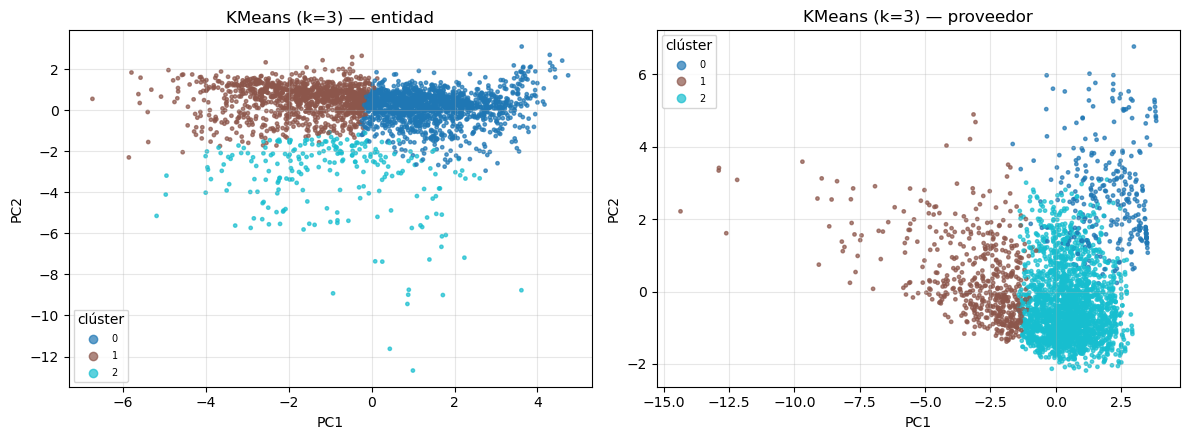

,sujeto,clave,nombre,region,cluster,dist_centro,n_procesos,monto
0,entidad,NOM:c7c9a8ec4ab9,AUTORIDAD NACIONAL DE CONTROL DEL MINISTERIO PÚBLICO,LIMA,2,9.91,5,2.880000e+05
1,entidad,NOM:c8e7e5156e13,UNIDAD EJECUTORA 411 SALUD JULCAN,JULCAN,2,9.53,6,1.103256e+06
2,entidad,NOM:80502bec0bff,MUNICIPALIDAD DISTRITAL DE LONGAR,RODRIGUEZ DE MENDOZA,0,9.16,13,NaN
3,entidad,NOM:319456546ff8,MUNICIPALIDAD DISTRITAL DE SAN JUAN DE SALINAS,AZANGARO,0,8.80,5,NaN
4,entidad,NOM:fe29ae720f35,MUNICIPALIDAD DISTRITAL DE CHURUJA,BONGARA,0,8.69,9,NaN
5,entidad,NOM:5d59866f8466,MUNICIPALIDAD DISTRITAL DE PACCHA - JAUJA,JAUJA,0,8.68,7,NaN
6,entidad,NOM:54819e004ed5,MUNICIPALIDAD DISTRITAL DE ATAVILLOS ALTO,HUARAL,0,8.67,5,NaN
7,entidad,NOM:dae4ea0ee29d,MUNICIPALIDAD DISTRITAL DE BALSAS,CHACHAPOYAS,0,8.63,7,NaN
8,entidad,NOM:c0792ffdb9cd,MUNICIPALIDAD DISTRITAL DE JOSE MARIA QUIMPER,CAMANA,0,8.61,6,NaN
9,entidad,NOM:2f509e29f945,MUNICIPALIDAD DISTRITAL DE RONDOCAN,ACOMAYO,0,8.52,6,NaN


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for i, s in enumerate(prep):
    mp = muestras[s]; lab = mp[f"k{k_sel[s]}"]
    sc_ = ax[i].scatter(mp.pc1, mp.pc2, c=lab, cmap="tab10", s=6, alpha=.7)
    ax[i].legend(*sc_.legend_elements(), title="clúster", fontsize=7, loc="best")
    ax[i].set_title(f"KMeans (k={k_sel[s]}) — {s}"); ax[i].set_xlabel("PC1"); ax[i].set_ylabel("PC2")
mostrar_fig("kmeans_pca")
display(top_dist)

#### Interpretación

- Cada fila de `perfiles` es una tipología; la columna `rasgos` resume qué la distingue (en σ respecto de la media).
  Nombrarlas a mano: ‹p. ej. "entidades grandes muy competidas", "entidades cautivas de contratación directa"›
- `pct_monto` vs `pct_actores`: un clúster con pocos actores y mucho monto concentra el gasto
- **Distancia al centroide:** los más lejanos no encajan en ninguna tipología. Es una **señal descriptiva** para revisión;
  puede tratarse de entidades singulares (p. ej. una autoridad nacional de infraestructura) y no de irregularidades

### 3. Escritura de resultados

In [11]:
tablas = {"curvas_k": curvas, "perfiles_kmeans": perfiles, "perfiles_z_kmeans": perfiles_z, "top_distancia": top_dist,
          **{f"muestra_k_{s}": mp for s, mp in muestras.items()}}
escritos = {nombre: guardar_tabla(df, nombre) for nombre, df in tablas.items()}
print(f"Escrito en {SECCION}/temp/{NOTEBOOK}/: {', '.join(escritos)}")

Escrito en 02_Clustering/temp/b_kmeans/: curvas_k, perfiles_kmeans, perfiles_z_kmeans, top_distancia, muestra_k_entidad, muestra_k_proveedor


#### a. Verificación

In [12]:
for nombre, n in escritos.items():
    leido = spark.read.parquet(str(tab_dir / nombre)).count()
    assert leido == n, f"{nombre}: esperaba {n}, leí {leido}"
    assert (web_dir / f"{nombre}.json").exists(), f"falta web/{nombre}.json"
figs = sorted(p.stem for p in fig_dir.glob("*.png"))
print(f"OK: {len(escritos)} tablas (parquet + json)" + (f" | {len(figs)} figuras: {', '.join(figs)}" if figs else ""))

OK: 6 tablas (parquet + json) | 2 figuras: eleccion_k, kmeans_pca


---
### 4. Cerrar sesión

In [13]:
spark.stop()